# 02 · Seasonal-naive baseline

The number every other model has to beat. Forecast for hour *t* = the load at the same hour, same weekday, last week (`load_lag_168h`). That value is always known 24 hours ahead, so it is a legitimate day-ahead forecast.

Time-ordered split: train to 2015, validation 2016, test 2017 onward (see `src/config.py`).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.features import load_features, add_groups, assign_split
from src.evaluate import summarize, error_by
from src.write_forecasts import write_forecasts

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "docs" / "results"; RES.mkdir(parents=True, exist_ok=True)

df = assign_split(add_groups(load_features()))
df.groupby("split")["ts"].agg(["min", "max", "count"])

,min,max,count
split,,,
test,2017-01-01,2018-08-03 00:00:00,13897
train,2002-01-09,2015-12-31 23:00:00,122520
validation,2016-01-01,2016-12-31 23:00:00,8784


## Baseline accuracy

In [3]:
df["forecast_mw"] = df["load_lag_168h"]          # seasonal naive
df["same_hour_yesterday"] = df["load_lag_24h"]    # diagnostic only

results = pd.concat([
    summarize(df, "forecast_mw", "seasonal_naive"),
    summarize(df, "same_hour_yesterday", "same_hour_yesterday (diagnostic)"),
])
results.round(2)

,model,split,MAPE_%,WAPE_%,RMSE_MW,MAE_MW,bias_MW,n_hours,peak_MAE_MW,peak_bias_MW,peak_MAPE_%,peak_hour_within_1h_%,n_days
0,seasonal_naive,validation,10.24,10.60,4602.00,3323.27,-60.90,8783,4033.88,-60.16,10.55,73.70,365
1,seasonal_naive,test,10.99,11.30,4794.30,3511.52,-66.97,13895,4388.97,-111.60,11.80,64.53,578
0,same_hour_yesterday (diagnostic),validation,6.57,6.65,2863.92,2084.36,-8.43,8783,2268.43,-1.81,6.13,71.78,365
1,same_hour_yesterday (diagnostic),test,7.32,7.40,3134.38,2300.29,-14.98,13895,2618.00,-19.46,7.18,66.09,578


Weekly lag is the official baseline because it keeps the weekday/weekend pattern. The yesterday row is only a diagnostic. Compare the two on weekends and Mondays (use `error_by(ev, "day_of_week", "same_hour_yesterday")`) to see whether the weekly lag earns its place.

## Where does the baseline fail?

,WAPE_%,MAE_MW,bias_MW,n_hours
day_type,,,,
holiday,13.96,4298.58,-180.12,672
weekday,10.62,3394.17,-65.84,15601
weekend,11.80,3456.62,-49.52,6405


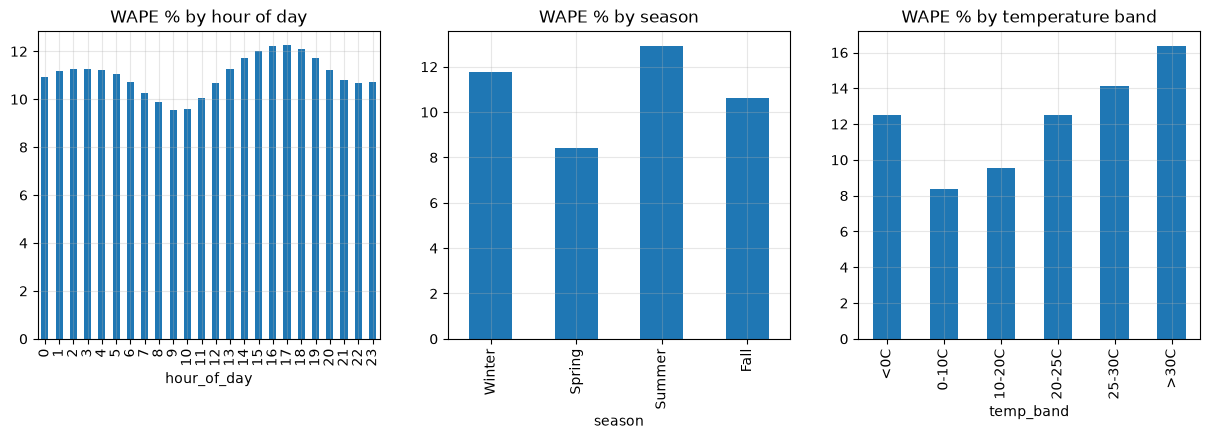

In [4]:
ev = df[df["split"].isin(["validation", "test"])].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
error_by(ev, "hour_of_day")["WAPE_%"].plot.bar(ax=axes[0], title="WAPE % by hour of day")
error_by(ev, "season")["WAPE_%"].reindex(["Winter", "Spring", "Summer", "Fall"]).plot.bar(ax=axes[1], title="WAPE % by season")
error_by(ev, "temp_band")["WAPE_%"].plot.bar(ax=axes[2], title="WAPE % by temperature band")
fig.savefig(FIG / "baseline_error_breakdown.png", dpi=150, bbox_inches="tight")
error_by(ev, "day_type").round(2)

In [5]:
ev_real = ev[~ev["is_imputed"]].assign(abs_err=lambda d: (d["forecast_mw"] - d["load_mw"]).abs())
worst = (ev_real.groupby("date").agg(MAE_MW=("abs_err", "mean"), day_type=("day_type", "first"),
                                     avg_temp_c=("temp_c", "mean"))
         .sort_values("MAE_MW", ascending=False).head(10).round(1))
worst   # expect holidays and weeks right after them (last week was a normal day)

,MAE_MW,day_type,avg_temp_c
date,,,
2018-01-12,14986.8,weekday,14.9
2016-09-16,14578.5,weekday,19.5
2017-06-13,14040.6,weekday,28.4
2018-07-03,13477.6,weekday,28.4
2018-06-18,13253.3,weekday,26.3
2016-09-17,13085.1,weekend,21.0
2018-01-13,13033.1,weekend,3.1
2016-09-10,12866.1,weekend,28.1
2018-06-19,12565.5,weekday,26.5


## Save the baseline

Forecasts go to `mart.fact_forecast` (so the dashboards read them) and the metrics to `docs/results/`.

In [6]:
n = write_forecasts(ev, "seasonal_naive")
print(f"wrote {n:,} rows to mart.fact_forecast")
results[results["model"] == "seasonal_naive"].to_csv(RES / "baseline_metrics.csv", index=False)

wrote 22,681 rows to mart.fact_forecast
